In [1]:
# Boilerplate for automatic reloading of modules on run and connecting to paths of local code.

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import torch
import numpy as np

from SurrogateModels import mfsnn, cokriging, mfkans
import multi_fidelity_functions

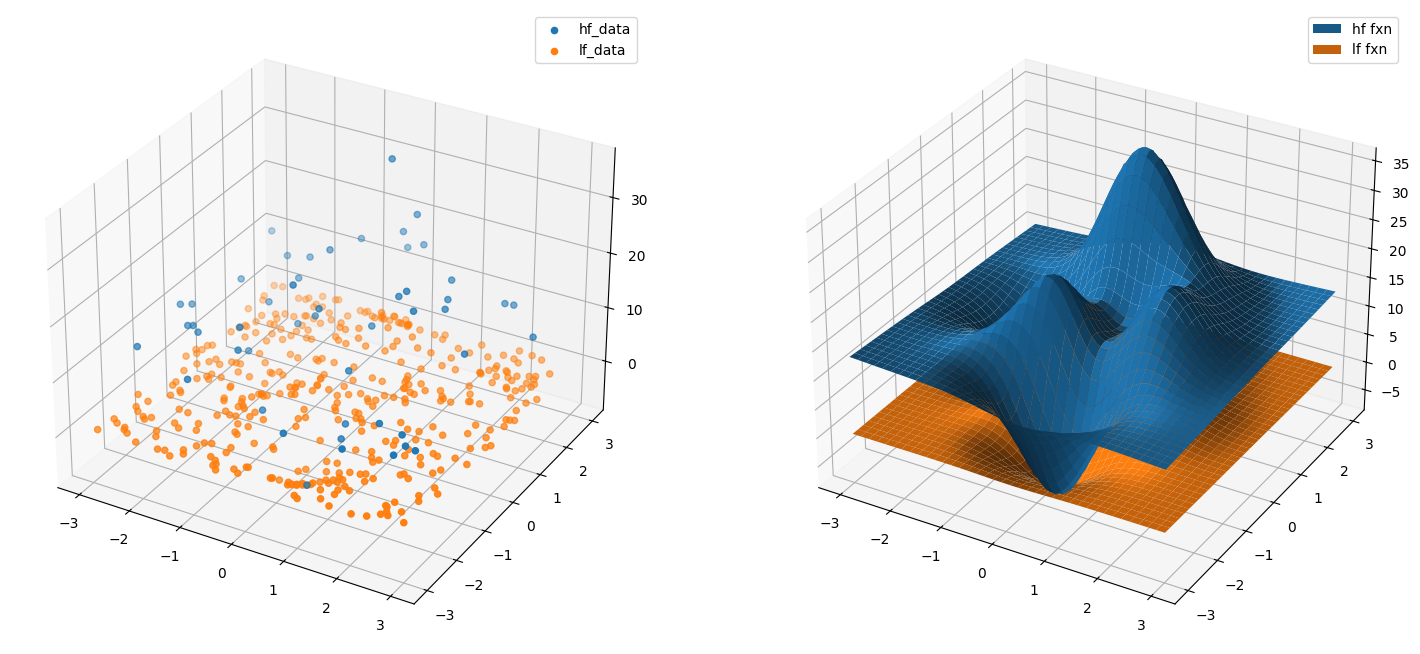

[[-1.97506488  1.81089932  0.928572    0.6691619 ]
 [ 1.29703794 -2.92975929  0.85372967  0.99340663]
 [ 1.12181467 -0.54389756  0.73858685  0.57970687]
 ...
 [-0.03006151 -2.22222463  0.08913065  0.98373869]
 [-2.49110169 -2.23756784  0.31307414  0.0631737 ]
 [ 0.44985847  1.04276745  0.58750858  0.99218295]]


In [11]:
from scipy.stats import qmc
import multi_fidelity_functions as mff
import matplotlib.pyplot as plt
from SurrogateModels import cokriging, model

# Define the mf example function for this notebook
mf_example = mff.PeaksShifted()
n_hf = 50
n_lf = 400
n_samp = 75


# Setup LatinHypercube sampling
def scale_samples(n, d, bounds, seed=1235):
    sampler = qmc.LatinHypercube(d=d, seed=seed)
    sample = sampler.random(n=n)
    for i, bound in enumerate(bounds):
        sample[:, i] = (bound[1] - bound[0]) * sample[:, i] + bound[0]
    return sample


bounds = mf_example.bounds
x1min = bounds[0][0]
x1max = bounds[0][1]
x2min = bounds[1][0]
x2max = bounds[1][1]

X_hf = scale_samples(n_hf, mf_example.dimensions, mf_example.bounds)
X_lf = scale_samples(n_lf, mf_example.dimensions, mf_example.bounds)
y_hf = mf_example.high_fidelity(X_hf)
y_lf = mf_example.low_fidelity(X_lf)

# take samples for plotting ground truth function
X_test = model.Model.generate_grid_array(x1min, x1max, x2min, x2max, n_samp)
y_hf_test = mf_example.high_fidelity(X_test)
y_lf_test = mf_example.low_fidelity(X_test)

# Set figure size for plots
fig = plt.figure(figsize=(18, 12))

# Plot the data
ax = fig.add_subplot(121, projection="3d")

sc = ax.scatter(X_hf[:, 0], X_hf[:, 1], y_hf[:, 0], label="hf_data")
sc = ax.scatter(X_lf[:, 0], X_lf[:, 1], y_lf[:, 0], label="lf_data")
ax.legend()

# Plot the actual surfaces of the lf and hf functions

X1, X2 = model.Model.generate_grid(x1min, x1max, x2min, x2max, n_samp)
y_samp_hf = y_hf_test.reshape(n_samp, n_samp)
y_samp_lf = y_lf_test.reshape(n_samp, n_samp)

ax = fig.add_subplot(122, projection="3d")
ax.plot_surface(X1, X2, y_samp_hf, label="hf fxn")
ax.plot_surface(X1, X2, y_samp_lf, label="lf fxn")
ax.legend()

plt.show()

sample = scale_samples(1000, 4, bounds)
print(sample)